#### Let's use a very simple and common differential equation: the natural decay of a substance. ####
dy/dt=−0.5y

    What this means: The rate of change of y (dy/dt) is proportional to its current value y, making it decay over time.

    Initial Condition: Let's set y=10 at t=0.

#### Apply the RK4 method to get values of dy/dy at ongoing time steps ####

Variable,Interpretation,Where the slope is calculated,Weight

1. k1​,Initial slope,"At the starting point (t,y)",1

2. k2​,Midpoint slope,"At the middle of the step, using k1​ to estimate the y value",2

3. k3​,Midpoint slope,"At the middle of the step, using k2​ to estimate the y value",2

4. k4​,End slope,"At the end of the step, using k3​ to estimate the y value",1

In [1]:
import matplotlib.pyplot as plt

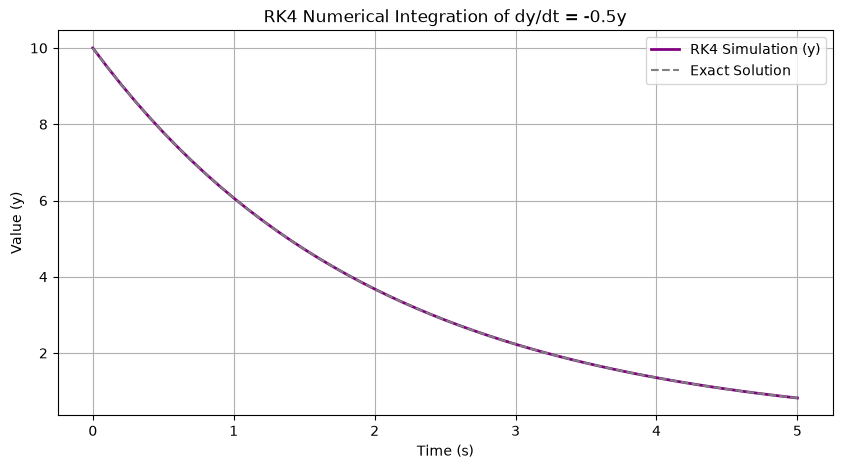

In [2]:
# DEFINE THE DIFFERENTIAL EQUATION (The RK4 'Function') ---
def dydt_func(y, t):
    """
    This function represents the rate of change (dy/dt).
    The system equation is: dy/dt = -0.5 * y
    """
    return -0.5 * y

# INITIAL SETUP ---
h = 0.1 # Time step (dt)
t = 0.0 # Initial time
y = 10.0 # Initial value (y0)

# Lists to store data for plotting
time_list = [t]
y_rk4_list = [y]

# Simulation Parameters
runtime_steps = 50 # Run for 50 steps (5 seconds simulated)

# THE RK4 SIMULATION LOOP ---
for step in range(runtime_steps):
    
    # 1. Calculate the four slopes (k1, k2, k3, k4)
    
    # k1: Slope at the start (t, y)
    k1 = h * dydt_func(y, t)
    
    # k2: Slope at the midpoint, using k1 for the estimate
    k2 = h * dydt_func(y + 0.5 * k1, t + 0.5 * h)
    
    # k3: Slope at the midpoint, using k2 for the estimate
    k3 = h * dydt_func(y + 0.5 * k2, t + 0.5 * h)
    
    # k4: Slope at the end point, using k3 for the estimate
    k4 = h * dydt_func(y + k3, t + h)
    
    # 2. Calculate the weighted average change (Delta y)
    delta_y = (k1 + 2*k2 + 2*k3 + k4) / 6.0
    
    # 3. Update the value (y) and time (t)
    y = y + delta_y
    t = t + h
    
    # 4. Store data for plotting
    time_list.append(t)
    y_rk4_list.append(y)

# PLOT THE RESULTS ---
plt.figure(figsize=(10, 5))
plt.plot(time_list, y_rk4_list, label='RK4 Simulation (y)', color='purple', linewidth=2)

# Plot the exact solution (y = 10 * exp(-0.5*t)) for comparison
import numpy as np
t_exact = np.array(time_list)
y_exact = 10 * np.exp(-0.5 * t_exact)
plt.plot(t_exact, y_exact, label='Exact Solution', color='gray', linestyle='--')

plt.title('RK4 Numerical Integration of dy/dt = -0.5y')
plt.xlabel('Time (s)')
plt.ylabel('Value (y)')
plt.grid(True)
plt.legend()
plt.show()

Visualizing the Four RK4 Slopes

Here is the code, based on the previous dy/dt ​= −0.5y example, designed to run just a single step and plot the estimated slopes.

Start: t=0.0, y=10.00
k1 (Start): slope=-5.00, delta_y_est=-2.50
k2 (Mid-1): t=0.2, y_est=8.75, slope=-4.38, delta_y_est=-2.19
k3 (Mid-2): t=0.2, y_est=8.91, slope=-4.45, delta_y_est=-2.23
k4 (End): t=0.5, y_est=7.77, slope=-3.89, delta_y_est=-1.94
----------------------------------------
RK4 Final Next Point: t=0.5, y=7.79


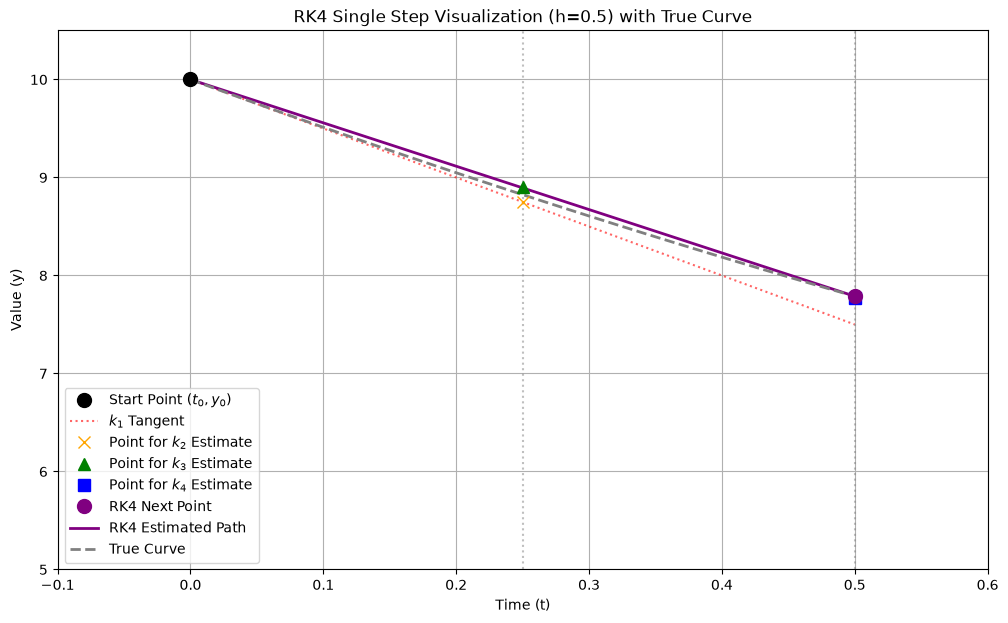

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. DEFINE THE DIFFERENTIAL EQUATION ---
def dydt_func(y, t):
    """ Rate of change function: dy/dt = -0.5 * y """
    return -0.5 * y

# --- 2. SINGLE STEP SETUP ---
h = 0.5       # Time step (dt) for clearer visualization
t0 = 0.0      # Start time
y0 = 10.0     # Start value (y at t0)

# --- 3. RK4 SLOPE CALCULATIONS ---

# 1. k1
k1_slope = dydt_func(y0, t0)
k1 = h * k1_slope
t1_est = t0
y1_est = y0 # The point for k1 is simply (t0, y0)

# 2. k2
k2_slope = dydt_func(y0 + 0.5 * k1, t0 + 0.5 * h)
k2 = h * k2_slope
t2_est = t0 + 0.5 * h
y2_val_at_mid = y0 + 0.5 * k1 # The y-value used to calculate k2_slope

# 3. k3
k3_slope = dydt_func(y0 + 0.5 * k2, t0 + 0.5 * h)
k3 = h * k3_slope
y3_val_at_mid = y0 + 0.5 * k2 # The y-value used to calculate k3_slope

# 4. k4
k4_slope = dydt_func(y0 + k3, t0 + h)
k4 = h * k4_slope
t4_est = t0 + h
y4_val_at_end = y0 + k3 # The y-value used to calculate k4_slope

# Weighted average to find the true change (delta_y)
delta_y_rk4 = (k1 + 2*k2 + 2*k3 + k4) / 6.0
y_rk4_next = y0 + delta_y_rk4
t_next = t0 + h

print(f"Start: t={t0:.1f}, y={y0:.2f}")
print(f"k1 (Start): slope={k1_slope:.2f}, delta_y_est={k1:.2f}")
print(f"k2 (Mid-1): t={t2_est:.1f}, y_est={y2_val_at_mid:.2f}, slope={k2_slope:.2f}, delta_y_est={k2:.2f}")
print(f"k3 (Mid-2): t={t2_est:.1f}, y_est={y3_val_at_mid:.2f}, slope={k3_slope:.2f}, delta_y_est={k3:.2f}")
print(f"k4 (End): t={t4_est:.1f}, y_est={y4_val_at_end:.2f}, slope={k4_slope:.2f}, delta_y_est={k4:.2f}")
print(f"----------------------------------------")
print(f"RK4 Final Next Point: t={t_next:.1f}, y={y_rk4_next:.2f}")

# --- 4. PLOTTING THE SLOPES AND THE TRUE CURVE ---
plt.figure(figsize=(12, 7))

# Plot the starting point
plt.plot(t0, y0, 'o', color='black', label='Start Point $(t_0, y_0)$', markersize=10, zorder=5)

# Plot k1 tangent
plt.plot([t0, t_next], [y0, y0 + k1_slope * h], ':', color='red', alpha=0.6, label='$k_1$ Tangent')

# Plot the points where k2, k3, k4 slopes are calculated
plt.plot(t0 + 0.5*h, y2_val_at_mid, 'x', color='orange', label='Point for $k_2$ Estimate', markersize=8, zorder=4)
plt.plot(t0 + 0.5*h, y3_val_at_mid, '^', color='green', label='Point for $k_3$ Estimate', markersize=8, zorder=4)
plt.plot(t0 + h, y4_val_at_end, 's', color='blue', label='Point for $k_4$ Estimate', markersize=8, zorder=4)

# Plot the final RK4 result
plt.plot(t_next, y_rk4_next, 'o', color='purple', label='RK4 Next Point', markersize=10, zorder=5)
plt.plot([t0, t_next], [y0, y_rk4_next], '-', color='purple', linewidth=2, label='RK4 Estimated Path')


# Plot the actual (exact) curve for comparison
# For dy/dt = -0.5y, the exact solution is y(t) = y0 * exp(-0.5 * t)
t_range = np.linspace(t0, t_next, 100)
y_exact_curve = y0 * np.exp(-0.5 * t_range)
plt.plot(t_range, y_exact_curve, '--', color='gray', label='True Curve', linewidth=2, zorder=3)


plt.title(f'RK4 Single Step Visualization (h={h}) with True Curve')
plt.xlabel('Time (t)')
plt.ylabel('Value (y)')
plt.legend()
plt.grid(True)
plt.ylim(y0 * 0.5, y0 * 1.05) # Adjust y-limits for better view
plt.xlim(t0 - 0.1, t_next + 0.1) # Adjust x-limits for better view
plt.axvline(x=t0 + 0.5*h, color='gray', linestyle=':', alpha=0.5, label='Midpoint')
plt.axvline(x=t0 + h, color='gray', linestyle=':', alpha=0.5, label='Endpoint')
plt.show()

Interpretation of the Plot

The plot shows how RK4 method cleverly probes the solution space to find the most accurate path:

    k1​ (Red Dashed Line): This is the initial slope calculated at your start point. If you only used this slope (Euler's method), you would end up on this red dashed line at t=1.0.

    k2​ (Orange X): You use k1​ to estimate the value at the midpoint, then you calculate a new slope (k2​) at that estimated midpoint. This slope is usually a much better representative of the entire interval.

    k3​ (Green Triangle): You use the improved slope k2​ to calculate an even better estimate of the value at the midpoint, and then calculate a new slope k3​. This is typically the most accurate midpoint slope.

    k4​ (Blue Square): Finally, you use k3​ to estimate the value at the endpoint (t=t0​+h) and calculate the slope k4​ there.

The RK4 Path (Purple Line) is the straight line from (t0​,y0​) to the final calculated point (tnext​,yRK4 next​). This path is determined by the weighted average of k1​,k2​,k3​, and k4​. By giving k2​ and k3​ (the midpoint estimates) double the weight, RK4 achieves its high accuracy.